# 分子動力学法：Lennard--Jones粒子

周期境界の立方体中で、Lennard--Jones粒子を速度Verlet法で時間発展させます。全ての量は換算単位です。

質量 $m$ の $N$ 粒子について
$$
\dot{\mathbf r}_i=\mathbf v_i,\qquad
m\dot{\mathbf v}_i=\sum_{j\ne i}\mathbf F_{ij}.
$$
長さ・エネルギー・質量に $\sigma,\epsilon,m$ を使い、$k_{\rm B}=1$ とします。密度は $\rho=N/V$ です。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(20270112)
n_particles = 64
density = 0.1
box_length = (n_particles / density)**(1 / 3)
volume = box_length**3
sigma = epsilon = mass = k_B = 1.0
cutoff = box_length / 2
temperature0 = 1.0
time_step = 0.01
num_steps = 1000

def initial_positions():
    n_side = int(np.ceil(n_particles**(1 / 3)))
    axis = (np.arange(n_side) + 0.5) * box_length / n_side
    grid = np.stack(np.meshgrid(axis, axis, axis, indexing="ij"), axis=-1)
    return grid.reshape(-1, 3)[:n_particles]

positions = initial_positions()
initial_velocities = rng.normal(
    0, np.sqrt(k_B * temperature0 / mass), size=(n_particles, 3)
)
velocities = initial_velocities.copy()


## Lennard--Jones相互作用と有限カットオフ

対ポテンシャルは
$$
V_{\rm LJ}(r)=4\epsilon\left[
(\sigma/r)^{12}-(\sigma/r)^6\right].
$$
最小像規約を使うため距離を $r_c=L/2$ で打ち切り、力とポテンシャルがカットオフで0になるようforce-shiftします。これは長距離の全LJ相互作用を厳密に足し上げる計算ではありません。

In [2]:
def raw_lj(r):
    q6 = (sigma / r)**6
    return 4 * epsilon * (q6**2 - q6)

def raw_lj_derivative(r):
    q6 = (sigma / r)**6
    return 24 * epsilon * (q6 - 2 * q6**2) / r

u_cut = raw_lj(cutoff)
du_cut = raw_lj_derivative(cutoff)

def pair_potential(r):
    if r >= cutoff:
        return 0.0
    return raw_lj(r) - u_cut - (r - cutoff) * du_cut

def pair_force_magnitude(r):
    if r >= cutoff:
        return 0.0
    return -(raw_lj_derivative(r) - du_cut)

assert pair_potential(cutoff) == 0.0
assert pair_force_magnitude(cutoff) == 0.0


## 周期境界・力・圧力

差ベクトルを最小像へ写し、粒子対を一度ずつ計算します。ビリアル圧力は
$$
P=\rho k_{\rm B}T_{\rm kin}
+\frac{1}{3V}\sum_{i<j}\mathbf r_{ij}\cdot\mathbf F_{ij}.
$$
このNotebookでは重心速度を差し引きません。したがって温度は $3N$ 自由度、理想項は $\rho k_{\rm B}T_{\rm kin}$ でそろえます。

In [3]:
def minimum_image(displacement):
    return displacement - box_length * np.rint(displacement / box_length)

def compute_forces(positions):
    forces = np.zeros_like(positions)
    potential_energy = 0.0
    virial_sum = 0.0
    for i in range(n_particles):
        for j in range(i + 1, n_particles):
            rij = minimum_image(positions[i] - positions[j])
            r = np.linalg.norm(rij)
            if r == 0:
                raise ValueError("overlapping particles")
            if r >= cutoff:
                continue
            fij = pair_force_magnitude(r) * rij / r
            forces[i] += fij
            forces[j] -= fij
            potential_energy += pair_potential(r)
            virial_sum += np.dot(rij, fij)
    virial_pressure = virial_sum / (3 * volume)
    return forces, potential_energy, virial_pressure

test_forces, _, _ = compute_forces(positions)
assert np.allclose(test_forces.sum(axis=0), 0.0, atol=1e-12)


## 速度Verlet法

位置・速度を整数時刻で保存する形は
$$
\begin{aligned}
\mathbf r_{n+1}&=\mathbf r_n+h\mathbf v_n+\tfrac12h^2\mathbf a_n,\\
\mathbf a_{n+1}&=\mathbf F(\mathbf r_{n+1})/m,\\
\mathbf v_{n+1}&=\mathbf v_n+\tfrac12h(\mathbf a_n+\mathbf a_{n+1}).
\end{aligned}
$$
leapfrog法では速度を半整数時刻に置きます。位置依存力では両者は同等の時間反転対称な更新で、どちらもエネルギーを厳密には保存しません。

In [4]:
def velocity_verlet_step(positions, velocities, forces):
    acceleration = forces / mass
    new_positions = (
        positions + velocities * time_step
        + 0.5 * acceleration * time_step**2
    ) % box_length
    new_forces, potential_energy, virial_pressure = compute_forces(
        new_positions
    )
    new_acceleration = new_forces / mass
    new_velocities = velocities + 0.5 * (
        acceleration + new_acceleration
    ) * time_step
    return (new_positions, new_velocities, new_forces,
            potential_energy, virial_pressure)

def kinetic_energy(velocities):
    return 0.5 * mass * np.sum(velocities**2)

def kinetic_temperature(velocities):
    return 2 * kinetic_energy(velocities) / (3 * n_particles * k_B)


## 初期状態と観測量

初期速度の各成分を平均0、分散$k_BT_0/m$の正規分布から引きます。有限標本の初期温度は$T_0$と完全一致しないため、最初の速度から測った$T_{kin}$と圧力を記録します。

In [5]:
forces, potential, virial_pressure = compute_forces(positions)
kinetic = kinetic_energy(velocities)
temperature = kinetic_temperature(velocities)
pressure = density * k_B * temperature + virial_pressure

times = [0.0]
kinetic_per_particle = [kinetic / n_particles]
potential_per_particle = [potential / n_particles]
total_per_particle = [(kinetic + potential) / n_particles]
temperatures = [temperature]
pressures = [pressure]
compressibility_factor = [pressure / (density * k_B * temperature)]

for step in range(num_steps):
    positions, velocities, forces, potential, virial_pressure = (
        velocity_verlet_step(positions, velocities, forces)
    )
    kinetic = kinetic_energy(velocities)
    temperature = kinetic_temperature(velocities)
    pressure = density * k_B * temperature + virial_pressure
    times.append((step + 1) * time_step)
    kinetic_per_particle.append(kinetic / n_particles)
    potential_per_particle.append(potential / n_particles)
    total_per_particle.append((kinetic + potential) / n_particles)
    temperatures.append(temperature)
    pressures.append(pressure)
    compressibility_factor.append(
        pressure / (density * k_B * temperature)
    )

times = np.asarray(times)
kinetic_per_particle = np.asarray(kinetic_per_particle)
potential_per_particle = np.asarray(potential_per_particle)
total_per_particle = np.asarray(total_per_particle)
temperatures = np.asarray(temperatures)
pressures = np.asarray(pressures)
compressibility_factor = np.asarray(compressibility_factor)

energy_drift = np.max(np.abs(total_per_particle - total_per_particle[0]))
assert np.isfinite(total_per_particle).all()
assert energy_drift < 0.05
print(f"initial measured T = {temperatures[0]:.3f} (T0={temperature0})")
print(f"energy drift per particle = {energy_drift:.3e}")
print(f"final P = {pressures[-1]:.3f}, final Z = {compressibility_factor[-1]:.3f}")


initial measured T = 1.070 (T0=1.0)
energy drift per particle = 4.805e-03
final P = 0.111, final Z = 0.777


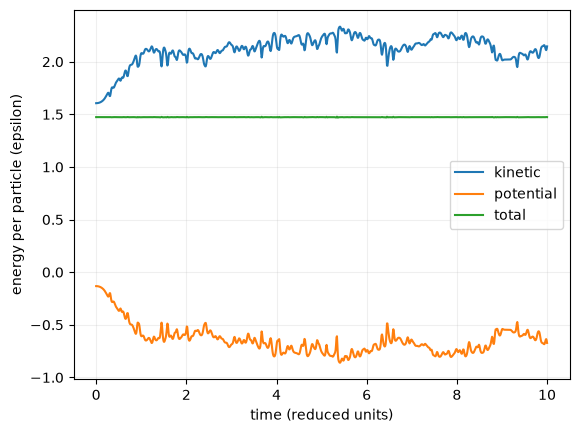

In [6]:
plt.plot(times, kinetic_per_particle, label="kinetic")
plt.plot(times, potential_per_particle, label="potential")
plt.plot(times, total_per_particle, label="total")
plt.xlabel("time (reduced units)")
plt.ylabel("energy per particle (epsilon)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


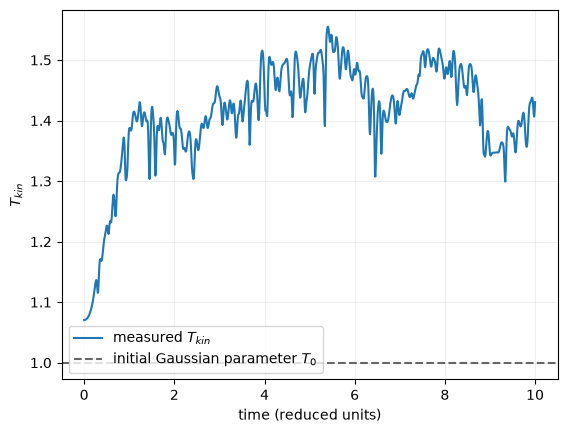

In [7]:
plt.plot(times, temperatures, label=r"measured $T_{kin}$")
plt.axhline(temperature0, color="0.4", ls="--",
            label=r"initial Gaussian parameter $T_0$")
plt.xlabel("time (reduced units)")
plt.ylabel(r"$T_{kin}$")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


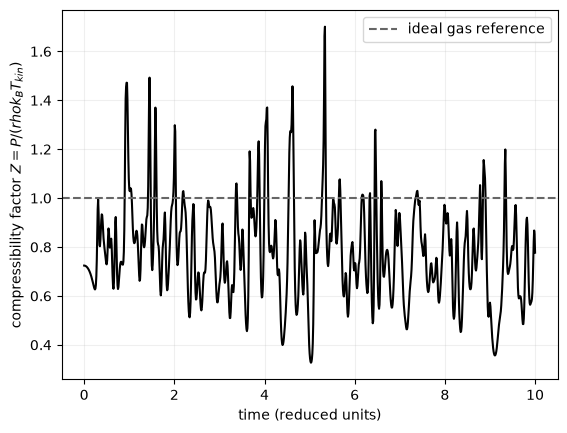

In [8]:
plt.plot(times, compressibility_factor, color="black")
plt.axhline(1.0, color="0.4", ls="--", label="ideal gas reference")
plt.xlabel("time (reduced units)")
plt.ylabel(r"compressibility factor $Z=P/(rho k_B T_{kin})$")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


## Maxwell--Boltzmann速度分布

各速度成分は初期化時に正規分布から引きます。速さ $v=|\mathbf v|$ の分布は
$$
p(v)=4\pi v^2
\left(\frac{m}{2\pi k_{\rm B}T_0}\right)^{3/2}
\exp\left(-\frac{mv^2}{2k_{\rm B}T_0}\right).
$$
以下のヒストグラムは64粒子からの一回の初期標本です。有限標本なので理論曲線と完全には一致しません。

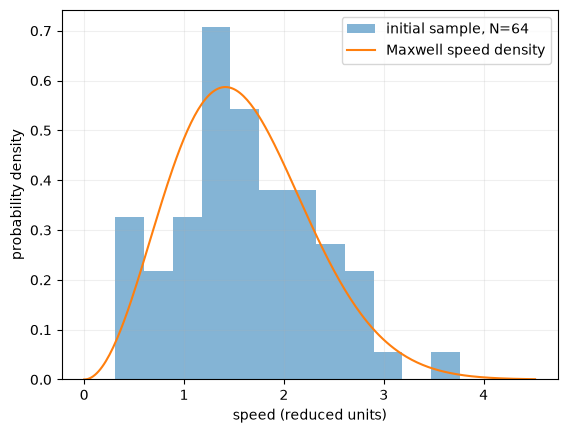

In [9]:
initial_speeds = np.linalg.norm(initial_velocities, axis=1)
speed = np.linspace(0, max(initial_speeds) * 1.2, 250)
maxwell_speed = (
    4 * np.pi * speed**2
    * (mass / (2 * np.pi * k_B * temperature0))**1.5
    * np.exp(-mass * speed**2 / (2 * k_B * temperature0))
)
plt.hist(initial_speeds, bins=12, density=True, alpha=0.55,
         label="initial sample, N=64")
plt.plot(speed, maxwell_speed, label="Maxwell speed density")
plt.xlabel("speed (reduced units)")
plt.ylabel("probability density")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


### 演習

- 密度、時間刻み、粒子数を変えて圧力とエネルギーの変化を比べる。
- 速度Verlet法とleapfrog法の時刻配置を書き、位置・速度の配列がどの時刻にあるか確認する。
- カットオフを変えたとき、周期境界と力・エネルギーの滑らかさが結果にどう影響するか調べる。